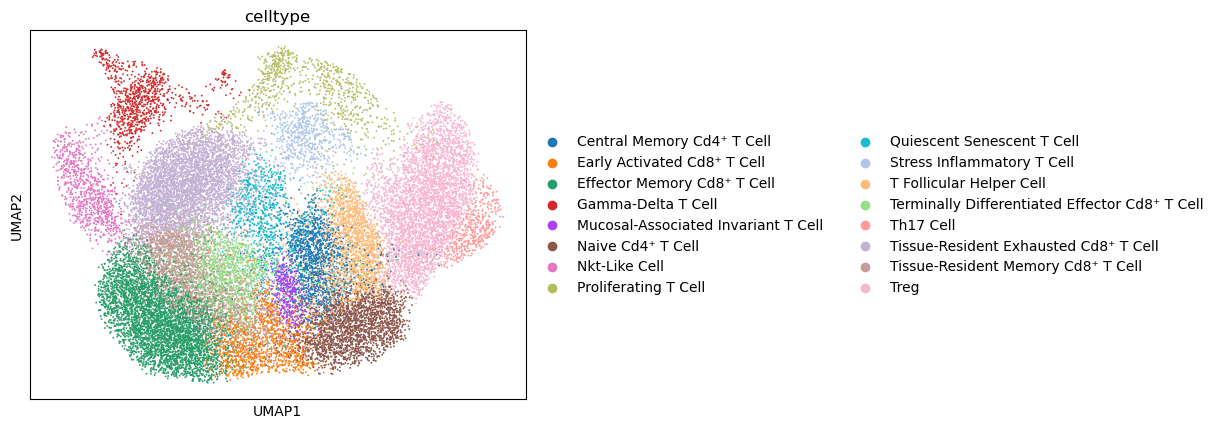

In [7]:
import scanpy as sc
adata_T = sc.read("./h5ad/adata_T.h5ad")
sc.pl.umap(adata_T, color=["celltype"], size=7, alpha=1.0)

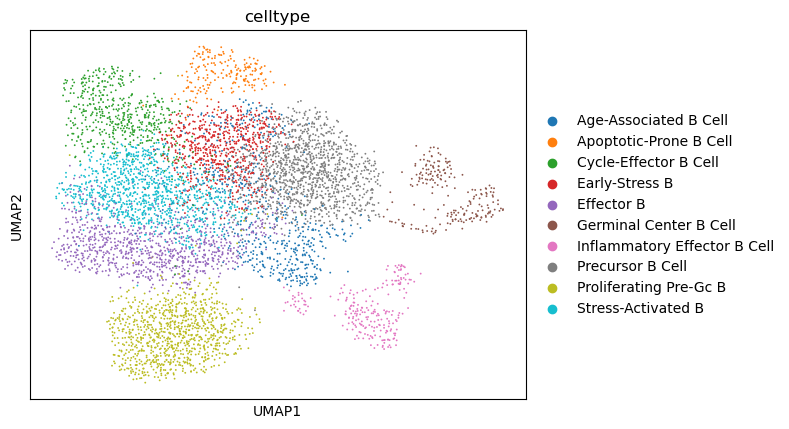

In [9]:
adata_B = sc.read("./h5ad/adata_B.h5ad")
sc.pl.umap(adata_B, color=["celltype"], size=7, alpha=1.0)

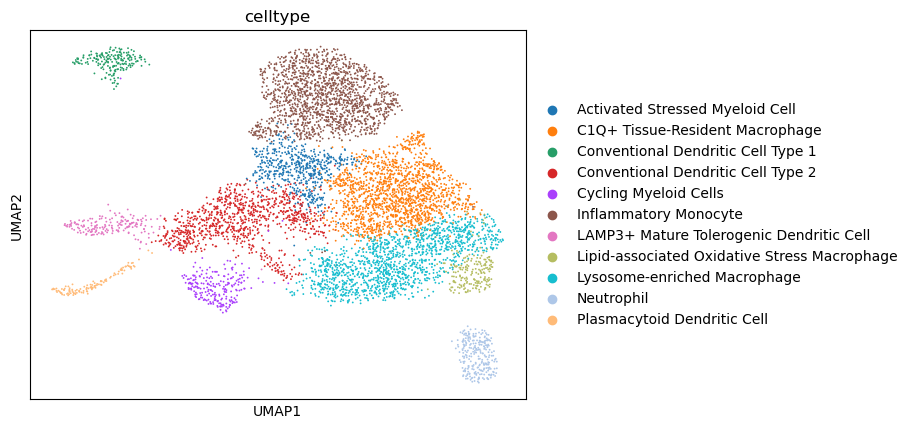

In [10]:
adata_myeloid = sc.read("./h5ad/adata_myeloid.h5ad")
sc.pl.umap(adata_myeloid, color=["celltype"], size=7, alpha=1.0)

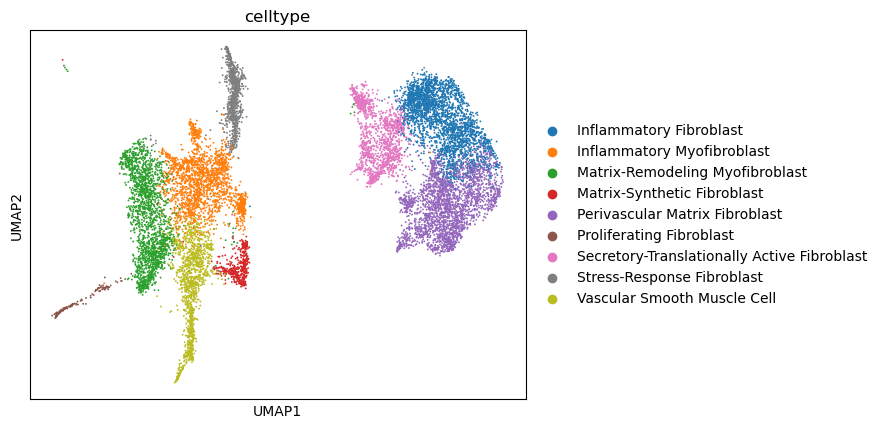

In [12]:
adata_fibroblast = sc.read("./h5ad/adata_fibroblast.h5ad")
sc.pl.umap(adata_fibroblast, color=["celltype"], size=7, alpha=1.0)

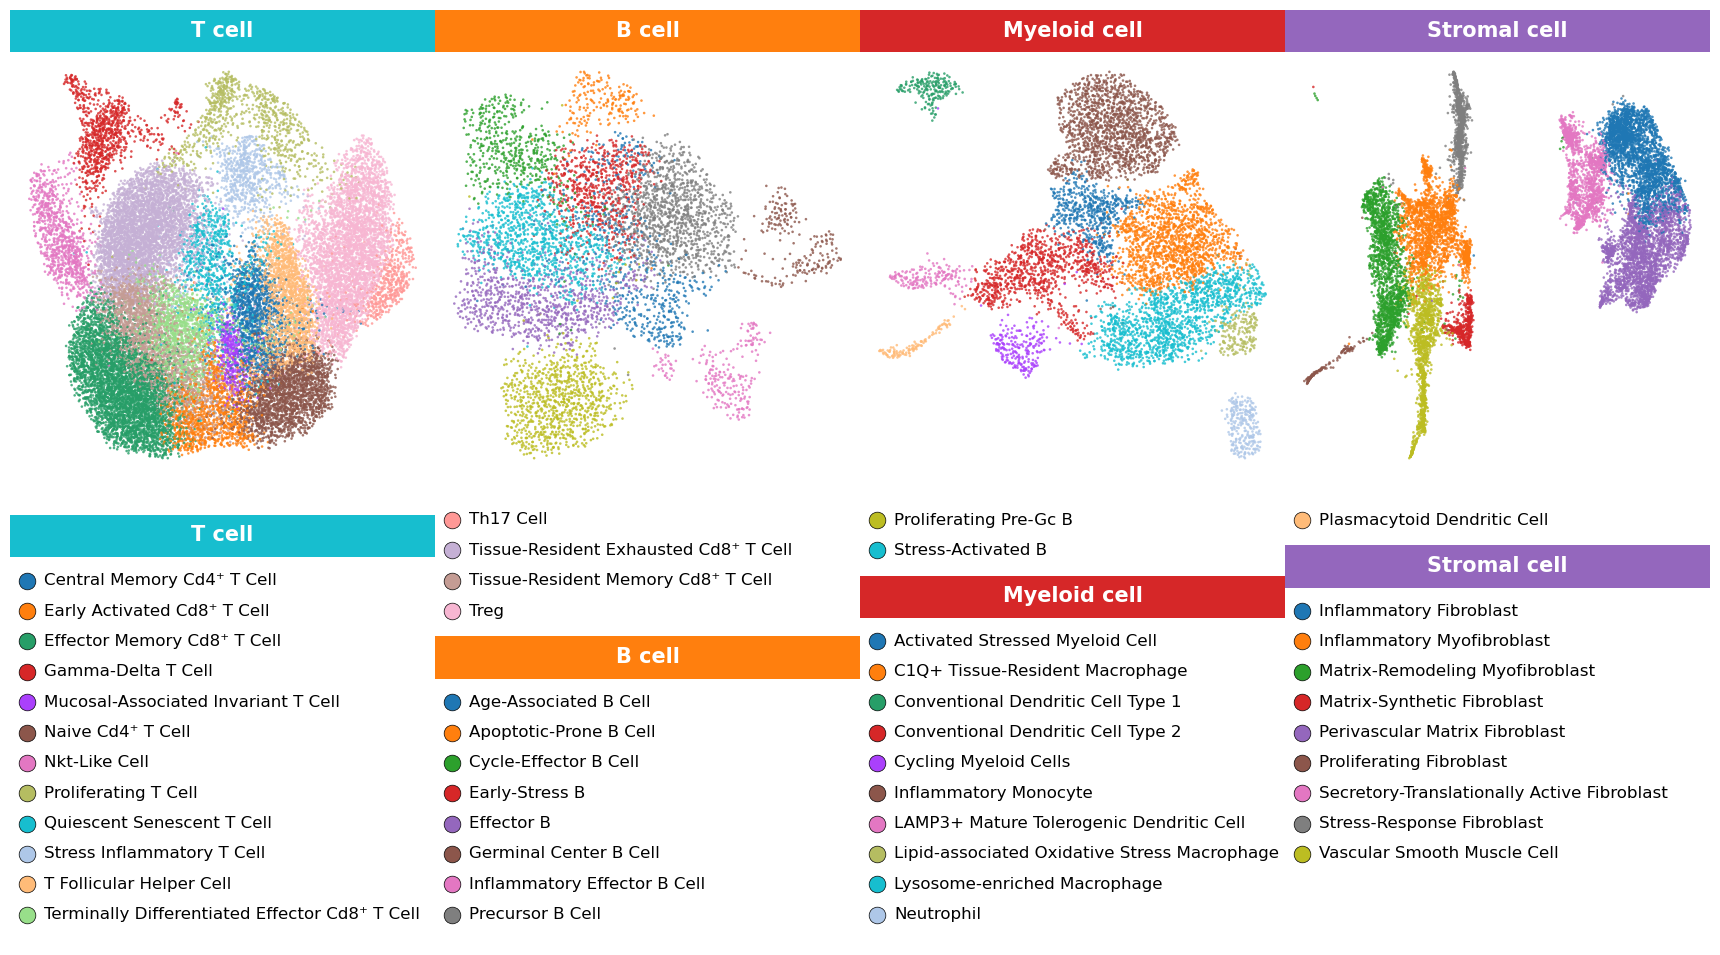

In [16]:
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.patches import Rectangle, Circle
import numpy as np

# Assume you already have:
# adata_T, adata_B, adata_fibroblast, adata_myeloid
# Each contains .obs[‘celltype’] and .obsm[‘X_umap’]

# ----------------------------
# Data Preparation
# ----------------------------
adatas = [adata_T, adata_B, adata_myeloid, adata_fibroblast]
titles = ['T cell', 'B cell','Myeloid cell', 'Stromal cell']
color_map = {
        'B cell': '#ff7f0e',          
        'Endothelial cell': '#1f77b4',
        'Epithelial cell': '#7f7f7f', 
        'Stromal cell': '#9467bd',  
        'Muscle cell': '#8c564b',     
        'Myeloid cell': '#d62728',
        'Plasma cell': '#bcbd22',     
        'T cell': '#17becf'           
    }
colors_list = ['#17becf','#ff7f0e','#d62728','#9467bd'] 

# ----------------------------
# Create a Canvas
# ----------------------------
size = 17
fig = plt.figure(figsize=(size, 1.1*size/2), constrained_layout=False)
gs = fig.add_gridspec(
    3, 4,           # 3 rows: Row 1 is the UMAP plot, row 0 is the title bar, and row 2 is the legend
    height_ratios=[0.1, 1.0, 1.1],
    hspace=0, wspace=0,
    left=0.0, right=1.0, top=1.0, bottom=0.0
)

# ----------------------------
# Row 1：UMAP plot
# ----------------------------
axes = []
for col in range(4):
    ax = fig.add_subplot(gs[1, col])
    axes.append(ax)  

for col, (ax, adata) in enumerate(zip(axes, adatas)):
    # draw UMAP plot
    sc.pl.umap(adata, color='celltype', size=14, alpha=0.8,
               show=False, ax=ax, legend_loc=None, frameon=False,title="")
    
    # Remove the border
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    
    # Remove Axis Labels and Ticks
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')

# ----------------------------
# Row 1：title bar
# ----------------------------
for col, title, color in zip(range(4), titles, colors_list):
    ax_title = fig.add_subplot(gs[0, col])
    ax_title.axis('off')
    ax_title.add_patch(Rectangle((0, 0), 1, 1, facecolor=color))
    ax_title.text(0.5, 0.5, title, ha='center', va='center', fontsize=15, color='white', fontweight='bold')

# ----------------------------
# Row 2：Bottom Legend (1×4 layout, listing all cell types and groups in order)
# ----------------------------
legend_ax = fig.add_subplot(gs[2, :])
legend_ax.axis('off')

# === Build all legend entries (including group headings and cell types) ===
entries = []  # Format for each item: (‘group’, title, color) or (‘cell’, ct, color)

for adata, group_name, color in zip(adatas, titles, colors_list):
    # Calculate the starting index for this group, to be used for global numbering
    start_idx = len(entries) + 1

     # Insert Group Heading Entry
    entries.append(('group', group_name, color))
    entries.append(('group', group_name, color))
    
    # For each celltype in this group, add it to entries
    for ct in adata.obs['celltype'].cat.categories:
        cell_color = adata.uns['celltype_colors'][adata.obs['celltype'].cat.categories.get_loc(ct)]
        entries.append(('cell', ct, cell_color))
        

# === Layout Parameters ===
n_rows = len(entries)//4 + (0 if len(entries)%4==0 else 1)
col_width = 0.25
row_height = 1.0 /n_rows        # 每行高度

# === Calculating the Position of Each Entry ===
for idx, (etype, name, color) in enumerate(entries):
    col_idx = idx // n_rows      # 从左到右循环
    row_idx = idx % n_rows     # 从上到下递增

    x0 = col_idx * col_width
    y_pos = 0.9 - row_idx * row_height  # 从上往下排
    
    if etype == 'group':
        if entries[idx+1][0] == 'group':
            continue
        # Creating Group Headings: Horizontal Bar + White Text
        rect = Rectangle((x0, y_pos - row_height * 0.3+0.005), col_width, 0.1,
                         facecolor=color, edgecolor='none')
        legend_ax.add_patch(rect)
        legend_ax.text(x0 + col_width / 2, y_pos+0.5*row_height, name,
                       ha='center', va='center', fontsize=15,
                       color='white', fontweight='bold')
    else:
        # Drawing Cell Types: Small Circles + Text
        marker = plt.Line2D([x0 + 0.01], [y_pos], # X 和 Y 坐标
                        marker='o', 
                        markerfacecolor=color, 
                        markersize=12,
                        linestyle='None',
                        markeredgecolor='black', 
                        markeredgewidth=0.5)
        legend_ax.add_artist(marker)
        legend_ax.text(x0 + 0.02, y_pos, f'{name}',
                       ha='left', va='center', fontsize=12, color='black')

# Set `ylim` to prevent clipping
legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(-0.1, 1.0)
plt.show()